In [2]:
import sys
import os

import numpy as np
import pandas as pd

from tqdm.notebook import tqdm
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE

src_path = os.path.abspath(os.path.join(os.getcwd(), "..", "..", "preliminar_phase_submision"))
if src_path not in sys.path:
    sys.path.append(src_path)
from team_code import data_cleaning_main
from helper_functions.feature_transformer import FeatureTransformer, calculate_purity, ordinal_columns, scale_ordinal_features

input_file = "/Users/uche/Sepsis_Hackathon/The-2024-Pediatric-Sepsis-Challenge/preliminar_phase_submision/training_data/SyntheticData_Training.csv"
_ = data_cleaning_main(input_file)
data = pd.read_csv("cleaned_data.csv")

In [3]:
# transform the cleaned dataset -> scale numerical features, one-hot encode nominal, rank ordinal categories
transformer = FeatureTransformer()
transformer.fit(data)
transformed_df = transformer.transform(data)


TARGET = "inhospital_mortality"
y = transformed_df[TARGET]
X = transformed_df.drop(columns=[TARGET])
X_scaled = scale_ordinal_features(X, ordinal_columns)

# extract categorical features and their indices
categorical_features = data.select_dtypes(exclude=['number']).columns.tolist() # X cannot be used
# updating the categorical features with one-hot encoded nominal features
nominal_features = ['deliveryloc_adm', 'caregivermarried_adm', 'cookloc_adm',
                                 'lightfuel_adm']
categorical_features = [col for col in categorical_features if col not in nominal_features]
one_hot_encoded_columns = [col for nominal_feature in nominal_features for col in X.columns if col.startswith(nominal_feature)]
categorical_features.extend(one_hot_encoded_columns)

# extract categorical indices -> Required for KPrototype
categorical_indices = [X.columns.get_loc(col) for col in categorical_features]

# K Means with 7 clusters

<Axes: xlabel='Cluster'>

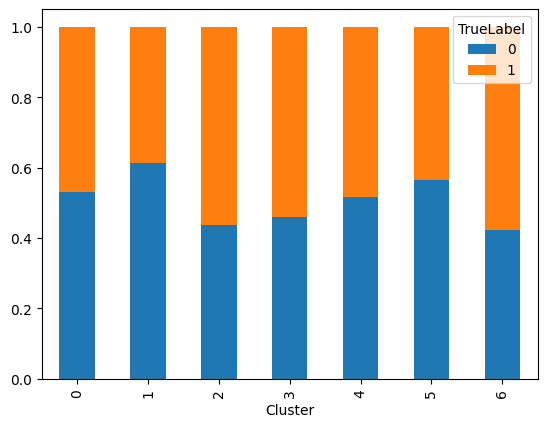

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Run KMeans with 7 clusters
num_clusters = 7
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

# Convert results to a DataFrame
df = pd.DataFrame({'Cluster': cluster_labels, 'TrueLabel': y})
df = df.groupby(['Cluster']).value_counts().unstack()

df = df.div(df.sum(axis=0), axis=1)
df.div(df.sum(axis=1), axis=0).plot(kind='bar', stacked=True)